# Retail Sales & Profitability Analysis

## Orders — Exploratory Data Analysis (EDA)

### Project Overview

This project analyses sales data from a fictional retail company operating in the United States.

The analysis is conducted from the perspective of a Junior Data Analyst working for an Italian consulting company.

The main goal is to understand sales performance, identify profitable and underperforming products, and provide insights to support better business decisions.

### Dataset Information

**Dataset:** Sample Superstore
**Source:** Tableau Sample Data
**Main Table:** Orders

The dataset contains information about customer orders, products, sales, quantities, discounts, profits and geographical locations.

### Analysis Objectives

* Analyse overall sales and profitability.
* Identify top-performing products and categories.
* Explore monthly and yearly sales trends.
* Compare sales performance across regions.
* Investigate the relationship between discounts and profits.
* Identify potential business improvement opportunities.

### Key Performance Indicators (KPIs)

* **Total Sales:** Total revenue generated.
* **Total Profit:** Total profit generated.
* **Total Orders:** Number of unique orders.
* **Total Units Sold:** Total quantity of products sold.
* **Profit Margin (%):** Percentage of sales retained as profit.
* **Average Order Value:** Average revenue per order.



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Load dataset
file_path = "sample_-_superstore.xls"
df_raw = pd.read_excel(file_path, sheet_name="Orders", engine="calamine")
df = df_raw[
    df_raw["Country/Region"] == "United States"
].copy()
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
4,5,US-2023-141817,2023-01-05,2023-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840


### 1. Overall Sales Performance


In [3]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_orders = df["Order ID"].nunique()
total_units = df["Quantity"].sum()
profit_margin = (total_profit / total_sales) * 100
average_order_value = total_sales / total_orders

In [4]:
print("=== OVERALL SALES PERFORMANCE ===")
print(f"Total Sales: ${total_sales:,.2f}")
print(f"Total Profit: ${total_profit:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Total Units Sold: {total_units:,}")
print(f"Profit Margin: {profit_margin:.2f}%")
print(f"Average Order Value: ${average_order_value:,.2f}")

=== OVERALL SALES PERFORMANCE ===
Total Sales: $2,297,200.86
Total Profit: $286,397.02
Total Orders: 5,009
Total Units Sold: 37,873
Profit Margin: 12.47%
Average Order Value: $458.61


### 2. Sales Trend Analysis

#### Objective

Analyse yearly and monthly sales trends to understand
business performance over time.

This analysis will help identify growth patterns,
changes in profitability and potential seasonal trends.

In [5]:
df["Order Year"] = df["Order Date"].dt.year
df[["Order Date", "Order Year"]].head()

,Order Date,Order Year
0,2023-01-03,2023
1,2023-01-04,2023
2,2023-01-04,2023
3,2023-01-04,2023
4,2023-01-05,2023


In [6]:
# Calculate yearly sales performance

yearly_sales = df.groupby("Order Year").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique"),
    Total_Quantity=("Quantity", "sum")
).reset_index()
yearly_sales

,Order Year,Total_Sales,Total_Profit,Total_Orders,Total_Quantity
0,2023,484247.4981,49543.9741,969,7581
1,2024,470532.5090,61618.6037,1038,7979
2,2025,609205.5980,81795.1743,1315,9837
3,2026,733215.2552,93439.2696,1687,12476


In [7]:
# Calculate yearly profit margin

yearly_sales["Profit_Margin"] = (
    yearly_sales["Total_Profit"] / 
    yearly_sales["Total_Sales"]
) * 100
yearly_sales.round(2)

,Order Year,Total_Sales,Total_Profit,Total_Orders,Total_Quantity,Profit_Margin
0,2023,484247.50,49543.97,969,7581,10.23
1,2024,470532.51,61618.60,1038,7979,13.10
2,2025,609205.60,81795.17,1315,9837,13.43
3,2026,733215.26,93439.27,1687,12476,12.74


Higher sales do not always mean higher profitability.

#### 2.1 Yearly Sales Trend

**Objective:** Visualise the company's annual sales performance and identify changes over time.

A line chart will help us understand whether sales are increasing or decreasing across the years.


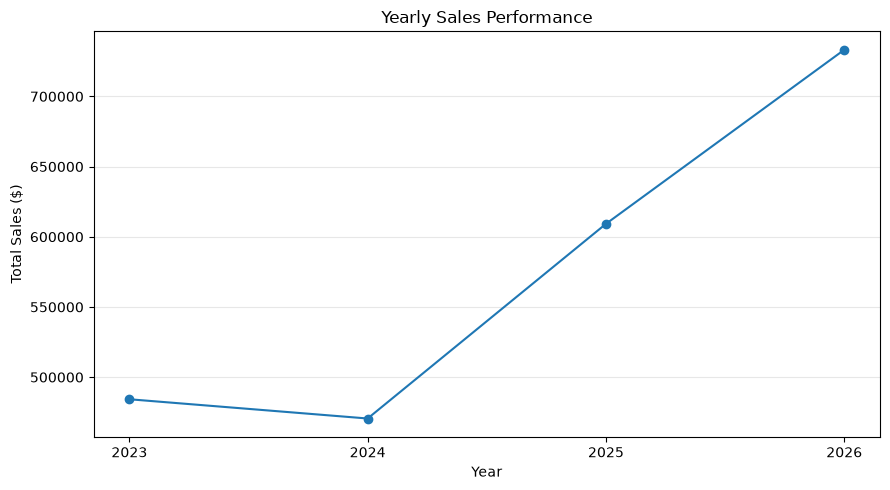

In [8]:
plt.figure(figsize=(9, 5))
plt.plot(
    yearly_sales["Order Year"],
    yearly_sales["Total_Sales"],
    marker="o"
)
plt.title("Yearly Sales Performance")
plt.xlabel("Year")
plt.ylabel("Total Sales ($)")
plt.xticks(yearly_sales["Order Year"])
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

#### 2.2 Year-over-Year (YoY) Sales Growth

**Objective:** Calculate the annual percentage change in sales
to measure business growth and identify performance trends.

In [9]:
yearly_sales = yearly_sales.sort_values("Order Year")
yearly_sales["Sales_YoY_Growth"] = (
yearly_sales["Total_Sales"].pct_change() * 100
)
yearly_sales[
    ["Order Year", "Total_Sales", "Sales_YoY_Growth"]
].round(2)

,Order Year,Total_Sales,Sales_YoY_Growth
0,2023,484247.50,NaN
1,2024,470532.51,-2.83
2,2025,609205.60,29.47
3,2026,733215.26,20.36


#### 2.3 Monthly Sales Analysis

**Objective:**

Analyse monthly sales and profit performance to identify trends, fluctuations and potential seasonal patterns.

This analysis will help the company understand how sales change throughout the year and support better business planning.


In [10]:
monthly_sales = (
    df.resample("MS", on="Order Date")[["Sales", "Profit"]]
    .sum()
    .reset_index()
)
monthly_sales = monthly_sales.rename(columns={
    "Sales": "Total_Sales",
    "Profit": "Total_Profit"
})
monthly_sales.head(10)

,Order Date,Total_Sales,Total_Profit
0,2023-01-01,14236.8950,2450.1907
1,2023-02-01,4519.8920,862.3084
2,2023-03-01,55691.0090,498.7299
3,2023-04-01,28295.3450,3488.8352
4,2023-05-01,23648.2870,2738.7096
5,2023-06-01,34595.1276,4976.5244
6,2023-07-01,33946.3930,-841.4826
7,2023-08-01,27909.4685,5318.1050
8,2023-09-01,81777.3508,8328.0994
9,2023-10-01,31453.3930,3448.2573


#### 2.4 Monthly Sales Trend Visualization

**Objective:** Visualise monthly sales performance to identify trends, fluctuations and potential seasonal patterns.

A line chart will help us understand how sales change over time and identify periods of high and low performance.


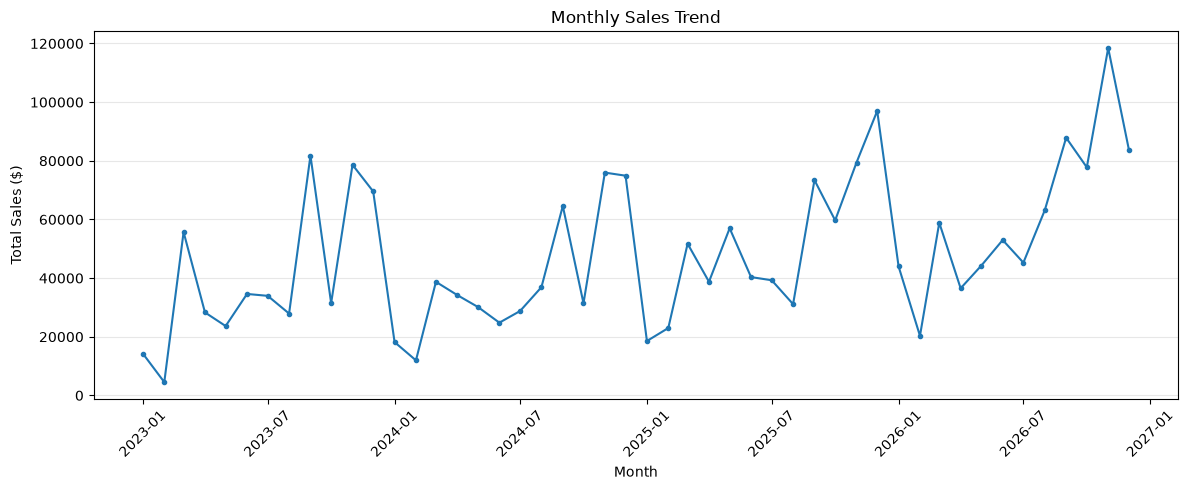

In [11]:
plt.figure(figsize=(12, 5))
plt.plot(
    monthly_sales["Order Date"],
    monthly_sales["Total_Sales"],
    marker="o",
    markersize=3

)
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales ($)")
plt.grid(axis="y", alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

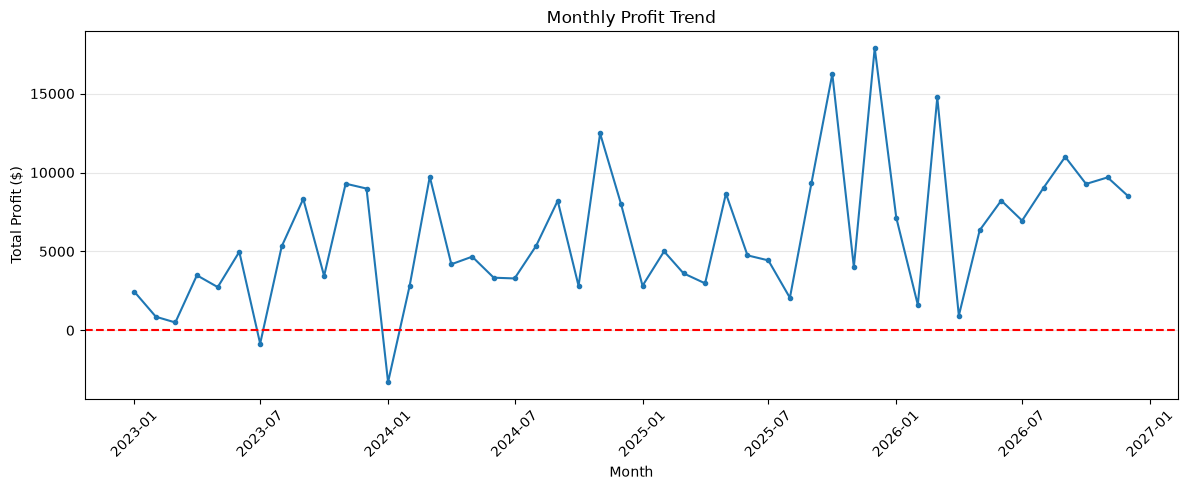

In [12]:
# Monthly Profit Trend
plt.figure(figsize=(12, 5))
plt.plot(
    monthly_sales["Order Date"],
    monthly_sales["Total_Profit"],
    marker="o",
    markersize=3
)
plt.title("Monthly Profit Trend")
plt.xlabel("Month")
plt.ylabel("Total Profit ($)")
plt.axhline(y=0, color="red", linestyle="--")
plt.grid(axis="y", alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### 2.5 Loss-Making Months Analysis

**Objective:**

Identify months with negative profits and investigate
periods of poor financial performance.

In [13]:
negative_profit_months = monthly_sales[monthly_sales["Total_Profit"] < 0]
negative_profit_months

,Order Date,Total_Sales,Total_Profit
6,2023-07-01,33946.3930,-841.4826
12,2024-01-01,18174.0756,-3281.0070


#### 2.6 Monthly Profit Margin Analysis

**Objective:**

Calculate the monthly profit margin to evaluate profitability over time.

This analysis helps identify the most profitable months and periods with low or negative profit margins.


In [14]:
monthly_sales["Profit_Margin"] = (
    monthly_sales["Total_Profit"] / 
    monthly_sales["Total_Sales"]
) * 100
monthly_sales[
    ["Order Date", "Total_Sales", "Total_Profit", "Profit_Margin"]
].round({
    "Total_Sales": 2,
    "Total_Profit": 2,
    "Profit_Margin": 2
})

,Order Date,Total_Sales,Total_Profit,Profit_Margin
0,2023-01-01,14236.90,2450.19,17.21
1,2023-02-01,4519.89,862.31,19.08
2,2023-03-01,55691.01,498.73,0.90
3,2023-04-01,28295.34,3488.84,12.33
4,2023-05-01,23648.29,2738.71,11.58
5,2023-06-01,34595.13,4976.52,14.39
6,2023-07-01,33946.39,-841.48,-2.48
7,2023-08-01,27909.47,5318.10,19.05
8,2023-09-01,81777.35,8328.10,10.18
9,2023-10-01,31453.39,3448.26,10.96


#### 2.7 Monthly Profit Margin Trend

**Objective:**

Visualise monthly profit margins to identify periods of high and low profitability.

This analysis helps evaluate how efficiently the company generates profit from sales over time.


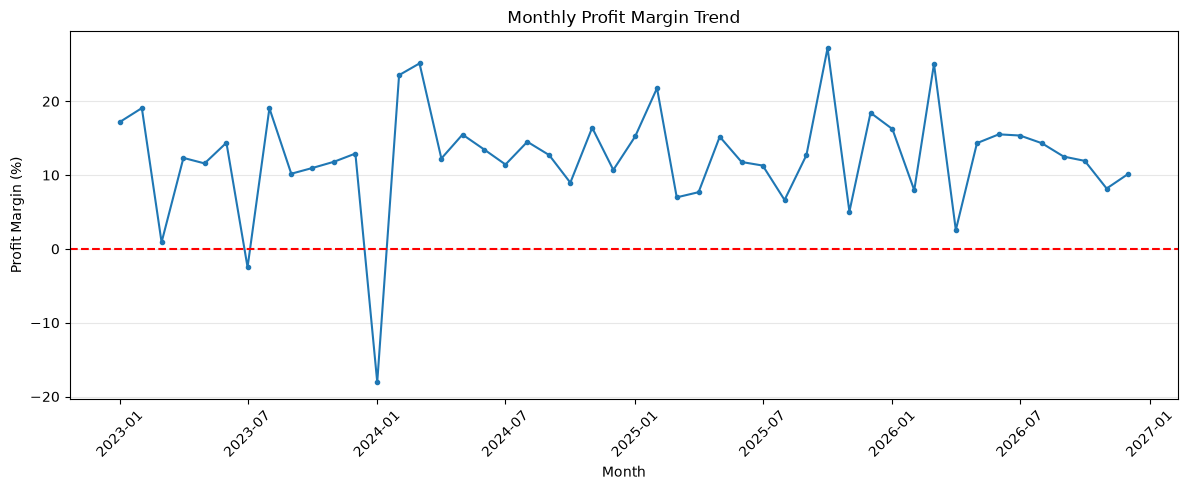

In [15]:
plt.figure(figsize=(12, 5))
plt.plot(
    monthly_sales["Order Date"],
    monthly_sales["Profit_Margin"],
    marker="o",
    markersize=3
)
plt.title("Monthly Profit Margin Trend")
plt.xlabel("Month")
plt.ylabel("Profit Margin (%)")
plt.axhline(y=0, color="red", linestyle="--")
plt.grid(axis="y", alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 3. Product & Category Performance Analysis

#### 3.1 Sales Performance by Category

**Objective:**

Analyse sales and profit performance across product categories.

This analysis will help identify the categories generating the highest revenue and profit, as well as those with lower profitability.


In [16]:
category_performance = df.groupby("Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Total_Orders=("Order ID", "nunique")
).reset_index()
category_performance

,Category,Total_Sales,Total_Profit,Total_Quantity,Total_Orders
0,Furniture,741999.7953,18451.2728,8028,1764
1,Office Supplies,719047.0320,122490.8008,22906,3742
2,Technology,836154.0330,145454.9481,6939,1544


In [17]:
# Calculate profit margin by category
category_performance["Profit_Margin"] = (
    category_performance["Total_Profit"] /
    category_performance["Total_Sales"]
) * 100
category_performance = category_performance.sort_values(
    by="Total_Sales",
    ascending=False
)
category_performance.round(2)

,Category,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Profit_Margin
2,Technology,836154.03,145454.95,6939,1544,17.40
0,Furniture,741999.80,18451.27,8028,1764,2.49
1,Office Supplies,719047.03,122490.80,22906,3742,17.04


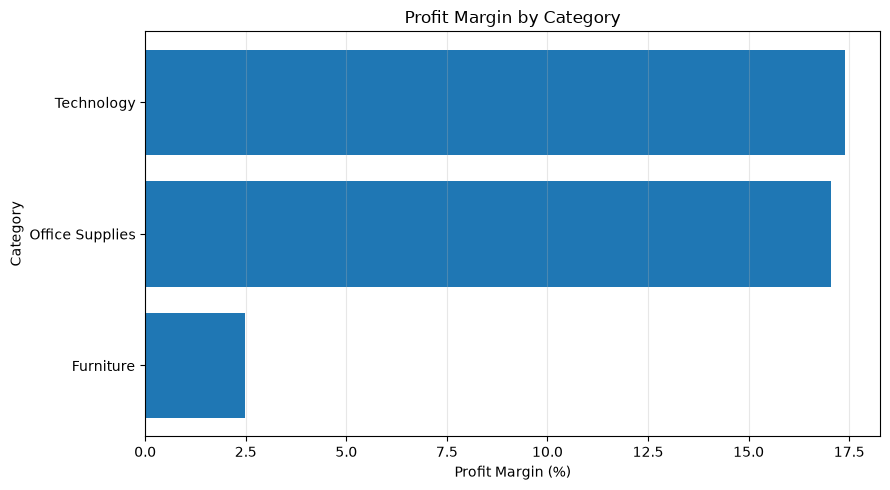

In [18]:
# Profit Margin by Category
category_sorted = category_performance.sort_values(
    "Profit_Margin",
    ascending=True
)
plt.figure(figsize=(9, 5))
plt.barh(
    category_sorted["Category"],
    category_sorted["Profit_Margin"]
)
plt.title("Profit Margin by Category")
plt.xlabel("Profit Margin (%)")
plt.ylabel("Category")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

#### 3.2 Furniture Sub-Category Performance

**Objective:**

Investigate the Furniture category to understand why its profit margin is significantly lower than other categories.

The analysis will compare sales, profit and profit margins across Furniture subcategories.

**Business Question:**

Which Furniture subcategories contribute most to the category's low profitability?


In [19]:
furniture = df[df["Category"] == "Furniture"]
furniture.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Order Year
5,6,US-2023-167199,2023-01-06,2023-01-10,Standard Class,ME-17320,Maria Etezadi,Home Office,United States,Henderson,...,South,FUR-CH-10004063,Furniture,Chairs,Global Deluxe High-Back Manager's Chair,2573.820,9,0.00,746.4078,2023
14,15,US-2023-105417,2023-01-07,2023-01-12,Standard Class,VS-21820,Vivek Sundaresam,Consumer,United States,Huntsville,...,Central,FUR-FU-10004864,Furniture,Furnishings,"Howard Miller 14-1/2"" Diameter Chrome Round Wa...",76.728,3,0.60,-53.7096,2023
18,19,US-2023-149020,2023-01-10,2023-01-15,Standard Class,AJ-10780,Anthony Jacobs,Corporate,United States,Springfield,...,South,FUR-FU-10000965,Furniture,Furnishings,"Howard Miller 11-1/2"" Diameter Ridgewood Wall ...",51.940,1,0.00,21.2954,2023
20,21,US-2023-130092,2023-01-11,2023-01-14,First Class,SV-20365,Seth Vernon,Consumer,United States,Dover,...,East,FUR-FU-10000010,Furniture,Furnishings,"DAX Value U-Channel Document Frames, Easel Back",9.940,2,0.00,3.0814,2023
21,22,US-2023-157147,2023-01-13,2023-01-18,Standard Class,BD-11605,Brian Dahlen,Consumer,United States,San Francisco,...,West,FUR-BO-10003034,Furniture,Bookcases,"O'Sullivan Elevations Bookcase, Cherry Finish",333.999,3,0.15,3.9294,2023


In [20]:
# Calculate sales and profit by sub-category
furniture_performance = furniture.groupby("Sub-Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum")
).reset_index()

furniture_performance["Profit_Margin"] = (
    furniture_performance["Total_Profit"] / 
    furniture_performance["Total_Sales"]
) * 100

furniture_performance = furniture_performance.sort_values(
    "Total_Profit",
    ascending=True
)
furniture_performance.round(2)

,Sub-Category,Total_Sales,Total_Profit,Total_Quantity,Profit_Margin
3,Tables,206965.53,-17725.48,1241,-8.56
0,Bookcases,114880.00,-3472.56,868,-3.02
2,Furnishings,91705.16,13059.14,3563,14.24
1,Chairs,328449.10,26590.17,2356,8.10


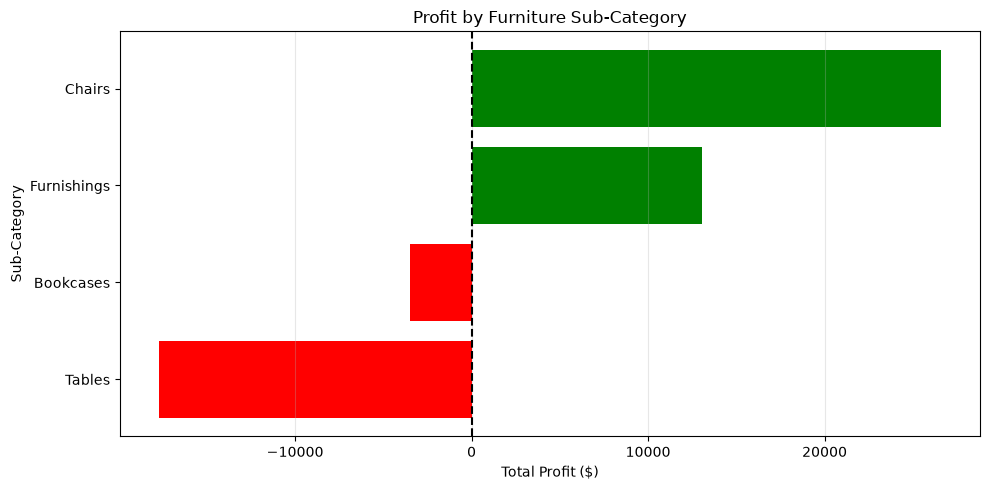

In [21]:
# Profit by Furniture Sub-Category
furniture_sorted = furniture_performance.sort_values(
    "Total_Profit",
    ascending=True
)
colors = [
    "red" if profit < 0 else "green"
    for profit in furniture_sorted["Total_Profit"]
]

plt.figure(figsize=(10, 5))
plt.barh(
    furniture_sorted["Sub-Category"],
    furniture_sorted["Total_Profit"],
    color=colors
)
plt.title("Profit by Furniture Sub-Category")
plt.xlabel("Total Profit ($)")
plt.ylabel("Sub-Category")
plt.axvline(x=0, color="black", linestyle="--")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

#### 3.3 Discount Analysis by Furniture Sub-Category

**Objective:**

Analyse average discounts across Furniture subcategories and compare them with profit margins.

This analysis will help identify whether higher discounts are associated with lower profitability.

**Business Questions:**

* Which Furniture subcategories have the highest average discounts?
* Do loss-making subcategories have higher discounts?
* Is there a relationship between discounts and profitability?


In [22]:
furniture_discounts = furniture.groupby("Sub-Category").agg(
    Average_Discount=("Discount", "mean"),
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum")
).reset_index()
furniture_discounts["Average_Discount"] *= 100

furniture_discounts["Profit_Margin"] = (
    furniture_discounts["Total_Profit"] / 
    furniture_discounts["Total_Sales"]
) * 100

furniture_discounts = furniture_discounts.sort_values(
    "Average_Discount",
    ascending=False
)
furniture_discounts.round(2)

,Sub-Category,Average_Discount,Total_Sales,Total_Profit,Profit_Margin
3,Tables,26.13,206965.53,-17725.48,-8.56
0,Bookcases,21.11,114880.00,-3472.56,-3.02
1,Chairs,17.02,328449.10,26590.17,8.10
2,Furnishings,13.83,91705.16,13059.14,14.24


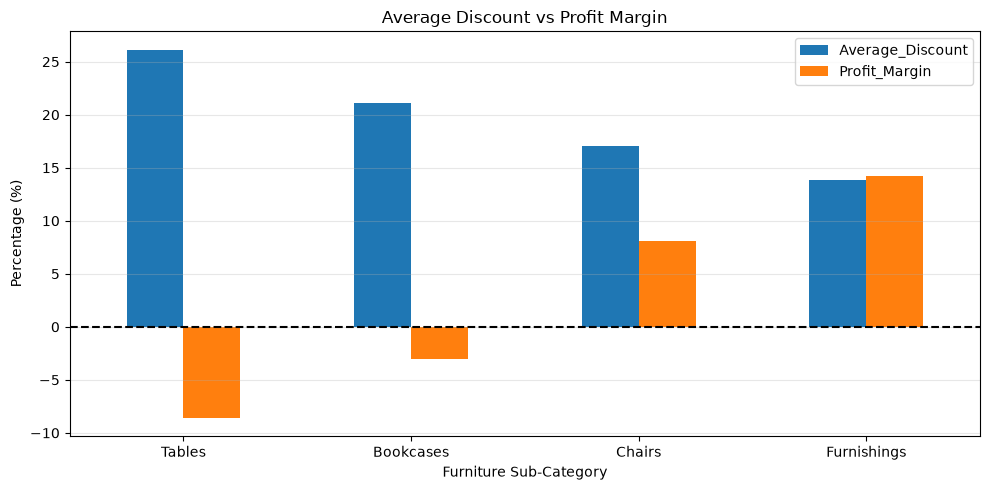

In [23]:
# Compare Average Discount and Profit Margin

discount_comparison = furniture_discounts.set_index(
    "Sub-Category"
)[["Average_Discount", "Profit_Margin"]]

ax = discount_comparison.plot(
    kind="bar",
    figsize=(10, 5)
)
plt.title("Average Discount vs Profit Margin")
plt.xlabel("Furniture Sub-Category")
plt.ylabel("Percentage (%)")
plt.axhline(y=0, color="black", linestyle="--")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

#### 3.4 Profitability by Discount Level

**Objective:**

Analyse sales and profitability across different discount levels within the Furniture category.

This analysis aims to identify whether higher discounts are associated with lower profit margins.

Sales will be grouped into discount ranges to compare their financial performance.


In [24]:
furniture_discounts_levels = furniture.copy()

furniture_discounts_levels["Discount_Group"] = pd.cut(
    furniture_discounts_levels["Discount"],
    bins=[-0.001, 0, 0.20, 0.40, 0.60, 1.0],
    labels=["No Discount", 
            "0-20%",
            "20-40%",
            "40-60%",
            "60-100%"
    ]
)
furniture_discounts_levels["Discount_Group"].value_counts(
    sort=False
)


Discount_Group
No Discount    836
0-20%          743
20-40%         324
40-60%         203
60-100%         15
Name: count, dtype: int64

In [25]:
# Calculate profitability by discount group

discount_performance = furniture_discounts_levels.groupby(
    "Discount_Group",
    observed=True,
    sort=False
).agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Sales_Lines=("Row ID", "count")

).reset_index()
discount_performance

,Discount_Group,Total_Sales,Total_Profit,Sales_Lines
0,No Discount,256025.2700,58133.0764,836
1,40-60%,33113.1440,-21308.9653,203
2,0-20%,290823.7845,14795.9525,743
3,60-100%,2459.3820,-3894.9394,15
4,20-40%,159578.2148,-29273.8514,324


In [26]:
# Calculate profit margin by discount group

discount_performance["Profit_Margin"] = (
    discount_performance["Total_Profit"] / 
    discount_performance["Total_Sales"]
) * 100
discount_performance = discount_performance.sort_values(
    "Discount_Group"
).reset_index(drop=True)
discount_performance.round(2)

,Discount_Group,Total_Sales,Total_Profit,Sales_Lines,Profit_Margin
0,No Discount,256025.27,58133.08,836,22.71
1,0-20%,290823.78,14795.95,743,5.09
2,20-40%,159578.21,-29273.85,324,-18.34
3,40-60%,33113.14,-21308.97,203,-64.35
4,60-100%,2459.38,-3894.94,15,-158.37


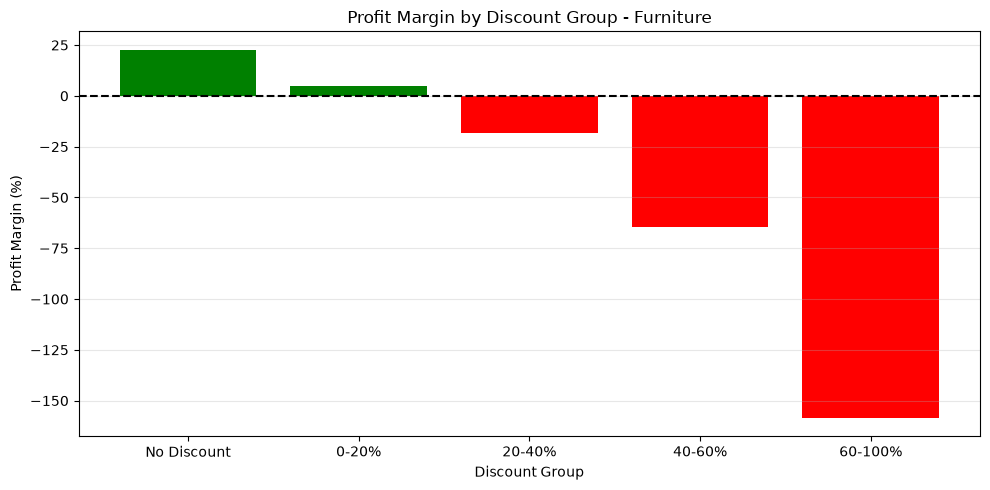

In [27]:
colors = [
    "red" if margin < 0 else "green"
    for margin in discount_performance["Profit_Margin"]
]
plt.figure(figsize=(10, 5))
plt.bar(
    discount_performance["Discount_Group"].astype(str),
    discount_performance["Profit_Margin"],
    color=colors
)
plt.title("Profit Margin by Discount Group - Furniture")
plt.xlabel("Discount Group")
plt.ylabel("Profit Margin (%)")
plt.axhline(y=0, color="black", linestyle="--")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

#### 3.5 Loss-Making Products — Tables and Bookcases

**Objective:**

Identify the products generating the largest financial losses within Tables and Bookcases.

The analysis will examine:

* Total Sales
* Total Profit
* Average Discount
* Profit Margin

**Business Question:**

Which products contribute most to the negative profitability of Tables and Bookcases?


In [28]:
loss_categories = furniture[
    furniture["Sub-Category"].isin(["Tables", "Bookcases"])
].copy()
loss_categories.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Order Year
21,22,US-2023-157147,2023-01-13,2023-01-18,Standard Class,BD-11605,Brian Dahlen,Consumer,United States,San Francisco,...,West,FUR-BO-10003034,Furniture,Bookcases,"O'Sullivan Elevations Bookcase, Cherry Finish",333.999,3,0.15,3.9294,2023
32,33,US-2023-149524,2023-01-14,2023-01-15,First Class,BS-11590,Brendan Sweed,Corporate,United States,Philadelphia,...,East,FUR-BO-10003433,Furniture,Bookcases,Sauder Cornerstone Collection Library,61.960,4,0.50,-53.2856,2023
39,40,US-2023-146591,2023-01-19,2023-01-20,First Class,TS-21340,Toby Swindell,Consumer,United States,Scottsdale,...,West,FUR-BO-10001972,Furniture,Bookcases,O'Sullivan 4-Shelf Bookcase in Odessa Pine,181.470,5,0.70,-320.5970,2023
68,69,US-2023-167997,2023-01-26,2023-01-29,First Class,CA-11965,Carol Adams,Corporate,United States,Rapid City,...,Central,FUR-BO-10004409,Furniture,Bookcases,"Safco Value Mate Series Steel Bookcases, Baked...",141.960,2,0.00,39.7488,2023
77,78,US-2023-117163,2023-01-27,2023-02-02,Standard Class,EJ-13720,Ed Jacobs,Consumer,United States,San Diego,...,West,FUR-TA-10003469,Furniture,Tables,Balt Split Level Computer Training Table,333.000,3,0.20,-16.6500,2023


In [29]:
# Calculate product-level performance

product_performance = loss_categories.groupby(
    ["Product ID", "Product Name", "Sub-Category"]
).agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Average_Discount=("Discount", "mean")
).reset_index()

product_performance["Average_Discount"] *= 100
product_performance["Profit_Margin"] = (
    product_performance["Total_Profit"] / 
    product_performance["Total_Sales"]
) * 100

product_performance = product_performance.sort_values(
    "Total_Profit",
    ascending=True
)
product_performance.head(10).round(2)

,Product ID,Product Name,Sub-Category,Total_Sales,Total_Profit,Average_Discount,Profit_Margin
50,FUR-TA-10000198,Chromcraft Bull-Nose Wood Oval Conference Tabl...,Tables,9917.64,-2876.12,28.00,-29.00
68,FUR-TA-10001889,Bush Advantage Collection Racetrack Conference...,Tables,9544.72,-1934.40,35.00,-20.27
70,FUR-TA-10001950,Balt Solid Wood Round Tables,Tables,6518.75,-1201.06,20.00,-18.42
99,FUR-TA-10004289,BoxOffice By Design Rectangular and Half-Moon ...,Tables,1706.25,-1148.44,48.33,-67.31
96,FUR-TA-10004154,"Riverside Furniture Oval Coffee Table, Oval En...",Tables,4446.18,-1147.40,30.00,-25.81
15,FUR-BO-10001972,O'Sullivan 4-Shelf Bookcase in Odessa Pine,Bookcases,2740.20,-975.10,42.14,-35.58
98,FUR-TA-10004256,Bretford “Just In Time” Height-Adjustable Mult...,Tables,5634.90,-964.19,22.50,-17.11
82,FUR-TA-10002958,"Bevis Oval Conference Table, Walnut",Tables,6942.07,-856.01,27.50,-12.33
75,FUR-TA-10002533,BPI Conference Tables,Tables,2241.87,-795.97,37.00,-35.50
5,FUR-BO-10000780,O'Sullivan Plantations 2-Door Library in Landv...,Bookcases,2946.37,-767.74,33.20,-26.06


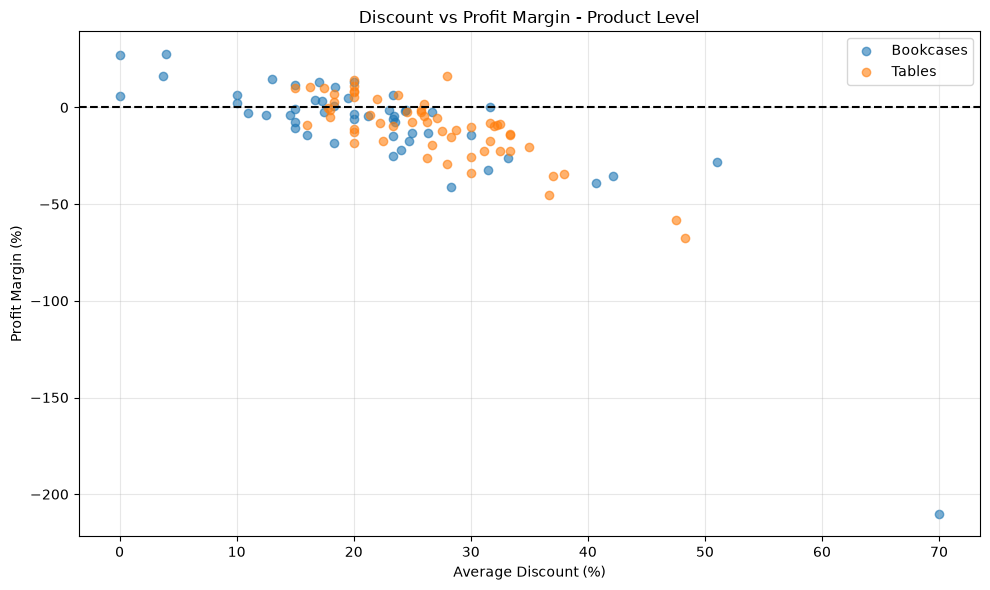

In [30]:
# Discount vs Profit Margin - Product Level

plt.figure(figsize=(10, 6))

for subcategory, group in product_performance.groupby("Sub-Category"):
    plt.scatter(
        group["Average_Discount"],
        group["Profit_Margin"],
        label=subcategory,
        alpha=0.6
    )

plt.axhline(y=0, color="black", linestyle="--")
plt.title("Discount vs Profit Margin - Product Level")
plt.xlabel("Average Discount (%)")
plt.ylabel("Profit Margin (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### 3.6 Pearson Correlation Analysis

**Objective:**

Measure the strength and direction of the linear relationship between average discounts and profit margins at the product level.

Pearson correlation will help us understand whether products with higher average discounts tend to have lower profit margins.


In [31]:
correlation = product_performance["Average_Discount"].corr(
    product_performance["Profit_Margin"]
)
print(f"Pearson Correlation: {correlation:.3f}")

Pearson Correlation: -0.780


In [32]:
# Calculate Spearman correlation

spearman_corr = product_performance["Average_Discount"].corr(
    product_performance["Profit_Margin"],
    method="spearman"
)
print(f"Pearson Correlation: {correlation:.3f}")
print(f"Spearman Correlation: {spearman_corr:.3f}")

Pearson Correlation: -0.780
Spearman Correlation: -0.707


#### 3.7 Top 10 Best-Selling Products

**Objective:**

Identify the products generating the highest sales revenue across all product categories.

This analysis will help management understand which products contribute most to overall sales performance.


In [33]:
top_products = df.groupby(
    ["Product ID", "Product Name", "Category"]
).agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum")
).reset_index()
top_products = top_products.sort_values(
    "Total_Sales",
    ascending=False
)
top_products.head(10).round(2)

,Product ID,Product Name,Category,Total_Sales,Total_Profit,Total_Quantity
1640,TEC-CO-10004722,Canon imageCLASS 2200 Advanced Copier,Technology,61599.82,25199.93,20
787,OFF-BI-10003527,Fellowes PB500 Electric Punch Plastic Comb Bin...,Office Supplies,27453.38,7753.04,31
1669,TEC-MA-10002412,Cisco TelePresence System EX90 Videoconferenci...,Technology,22638.48,-1811.08,6
82,FUR-CH-10002024,HON 5400 Series Task Chairs for Big and Tall,Furniture,21870.58,0.00,39
701,OFF-BI-10001359,GBC DocuBind TL300 Electric Binding System,Office Supplies,19823.48,2233.51,37
667,OFF-BI-10000545,GBC Ibimaster 500 Manual ProClick Binding System,Office Supplies,19024.50,760.98,48
1630,TEC-CO-10001449,Hewlett Packard LaserJet 3310 Copier,Technology,18839.69,6983.88,38
1657,TEC-MA-10001127,HP Designjet T520 Inkjet Large Format Printer ...,Technology,18374.90,4094.98,12
858,OFF-BI-10004995,GBC DocuBind P400 Electric Binding System,Office Supplies,17965.07,-1878.17,27
1443,OFF-SU-10000151,High Speed Automatic Electric Letter Opener,Office Supplies,17030.31,-262.00,11


In [34]:
# Identify Top 10 Most Profitable Products

top_profitable_products = top_products.sort_values(
    "Total_Profit",
    ascending=False
).head(10)
top_profitable_products[
    [
        "Product ID",
        "Product Name",
        "Category",
        "Total_Sales",
        "Total_Profit",
        "Total_Quantity"
    ]
].round(2)

,Product ID,Product Name,Category,Total_Sales,Total_Profit,Total_Quantity
1640,TEC-CO-10004722,Canon imageCLASS 2200 Advanced Copier,Technology,61599.82,25199.93,20
787,OFF-BI-10003527,Fellowes PB500 Electric Punch Plastic Comb Bin...,Office Supplies,27453.38,7753.04,31
1630,TEC-CO-10001449,Hewlett Packard LaserJet 3310 Copier,Technology,18839.69,6983.88,38
1637,TEC-CO-10003763,Canon PC1060 Personal Laser Copier,Technology,11619.83,4570.93,19
1657,TEC-MA-10001127,HP Designjet T520 Inkjet Large Format Printer ...,Technology,18374.90,4094.98,12
1693,TEC-MA-10003979,Ativa V4110MDD Micro-Cut Shredder,Technology,7699.89,3772.95,11
1656,TEC-MA-10001047,"3D Systems Cube Printer, 2nd Generation, Magenta",Technology,14299.89,3717.97,11
1541,TEC-AC-10002049,Plantronics Savi W720 Multi-Device Wireless He...,Technology,9367.29,3696.28,24
692,OFF-BI-10001120,Ibico EPK-21 Electric Binding System,Office Supplies,15875.92,3345.28,13
1643,TEC-MA-10000045,Zebra ZM400 Thermal Label Printer,Technology,6965.70,3343.54,6


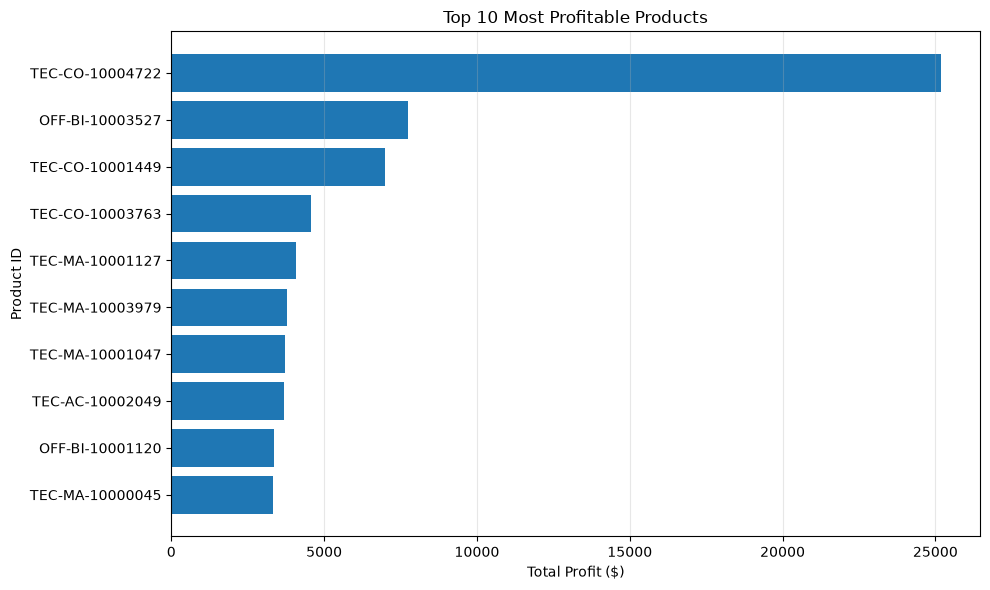

In [35]:
top_profit_sorted = top_profitable_products.sort_values(
    "Total_Profit",
    ascending=True
)
plt.figure(figsize=(10, 6))
plt.barh(
    top_profit_sorted["Product ID"],
    top_profit_sorted["Total_Profit"]
)
plt.title("Top 10 Most Profitable Products")
plt.xlabel("Total Profit ($)")
plt.ylabel("Product ID")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### 4. Regional Sales & Profitability Analysis

#### 4.1 Sales Performance by Region

**Objective:**

Analyse sales and profitability across different regions in the United States.

This analysis will help identify high-performing and underperforming regions and support better business decisions.

**Business Questions:**

* Which regions generate the highest sales?
* Which regions generate the highest profits?
* Which regions have the highest profit margins?
* Are there regions with high sales but low profitability?


In [36]:
# Calculate sales performance by region

region_performance = df.groupby("Region").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique"),
    Total_Quantity=("Quantity", "sum")
).reset_index()
region_performance

,Region,Total_Sales,Total_Profit,Total_Orders,Total_Quantity
0,Central,501239.8908,39706.3625,1175,8780
1,East,678781.2400,91522.7800,1401,10618
2,South,391721.9050,46749.4303,822,6209
3,West,725457.8245,108418.4489,1611,12266


In [37]:
# Calculate profit margin sales

region_performance["Profit_Margin"] = (
    region_performance["Total_Profit"] /
    region_performance["Total_Sales"]
) * 100
region_performance = region_performance.sort_values(
    "Total_Sales",
    ascending=False
)
region_performance.round(2)

,Region,Total_Sales,Total_Profit,Total_Orders,Total_Quantity,Profit_Margin
3,West,725457.82,108418.45,1611,12266,14.94
1,East,678781.24,91522.78,1401,10618,13.48
0,Central,501239.89,39706.36,1175,8780,7.92
2,South,391721.90,46749.43,822,6209,11.93


#### 4.2 Profit Margin by Region — Visualization

**Objective:**

Compare profit margins across the four US regions to identify differences in profitability.

This visualisation helps identify the most profitable regions and areas that may require further investigation.


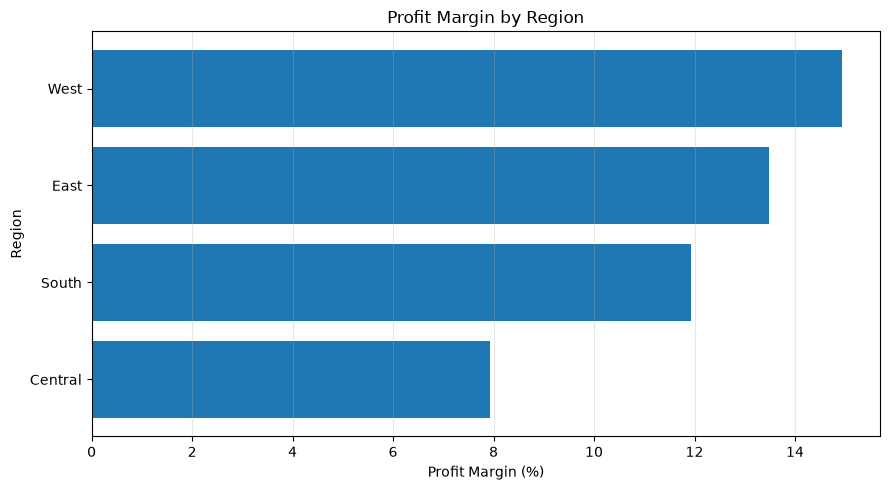

In [38]:
region_sorted = region_performance.sort_values(
    "Profit_Margin",
    ascending=True
)
plt.figure(figsize=(9, 5))
plt.barh(
region_sorted["Region"],
region_sorted["Profit_Margin"]
)
plt.title("Profit Margin by Region")
plt.xlabel("Profit Margin (%)")
plt.ylabel("Region")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

#### 4.3 Central Region — State Performance Analysis

**Objective:**

Investigate sales and profitability across states within the Central region.

The analysis aims to identify states with low or negative profits and understand which areas may require further investigation.

**Business Questions:**

* Which states generate the highest sales?
* Which states generate the lowest profits?
* Are there states generating financial losses?
* Which states have the lowest profit margins?


In [39]:
central_df = df[df["Region"] == "Central"].copy()
central_df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Order Year
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512,2023
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870,2023
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717,2023
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748,2023
14,15,US-2023-105417,2023-01-07,2023-01-12,Standard Class,VS-21820,Vivek Sundaresam,Consumer,United States,Huntsville,...,Central,FUR-FU-10004864,Furniture,Furnishings,"Howard Miller 14-1/2"" Diameter Chrome Round Wa...",76.728,3,0.6,-53.7096,2023


In [40]:
# Calculate sales and profit by state

state_performance = central_df.groupby("State/Province").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique"),
    Total_Quantity=("Quantity", "sum")
).reset_index()
state_performance

,State/Province,Total_Sales,Total_Profit,Total_Orders,Total_Quantity
0,Illinois,80166.1010,-12607.8870,276,1845
1,Indiana,53555.3600,18382.9363,73,578
2,Iowa,4579.7600,1183.8119,17,112
3,Kansas,2914.3100,836.4435,14,74
4,Michigan,76269.6140,24463.1876,117,946
5,Minnesota,29863.1500,10823.1874,44,331
6,Missouri,22205.1500,6436.2105,30,252
7,Nebraska,7464.9300,2037.0942,23,136
8,North Dakota,919.9100,230.1497,2,30
9,Oklahoma,19683.3900,4853.9560,34,247


In [41]:
# Calculate profit margin by state

state_performance["Profit_Margin"] = (
    state_performance["Total_Profit"] /
    state_performance["Total_Sales"]
) * 100
state_performance = state_performance.sort_values(
    "Total_Profit",
    ascending=True
)
state_performance.round(2)

,State/Province,Total_Sales,Total_Profit,Total_Orders,Total_Quantity,Profit_Margin
11,Texas,170188.05,-25729.36,487,3724,-15.12
0,Illinois,80166.10,-12607.89,276,1845,-15.73
8,North Dakota,919.91,230.15,2,30,25.02
10,South Dakota,1315.56,394.83,5,42,30.01
3,Kansas,2914.31,836.44,14,74,28.70
2,Iowa,4579.76,1183.81,17,112,25.85
7,Nebraska,7464.93,2037.09,23,136,27.29
9,Oklahoma,19683.39,4853.96,34,247,24.66
6,Missouri,22205.15,6436.21,30,252,28.99
12,Wisconsin,32114.61,8401.80,53,463,26.16


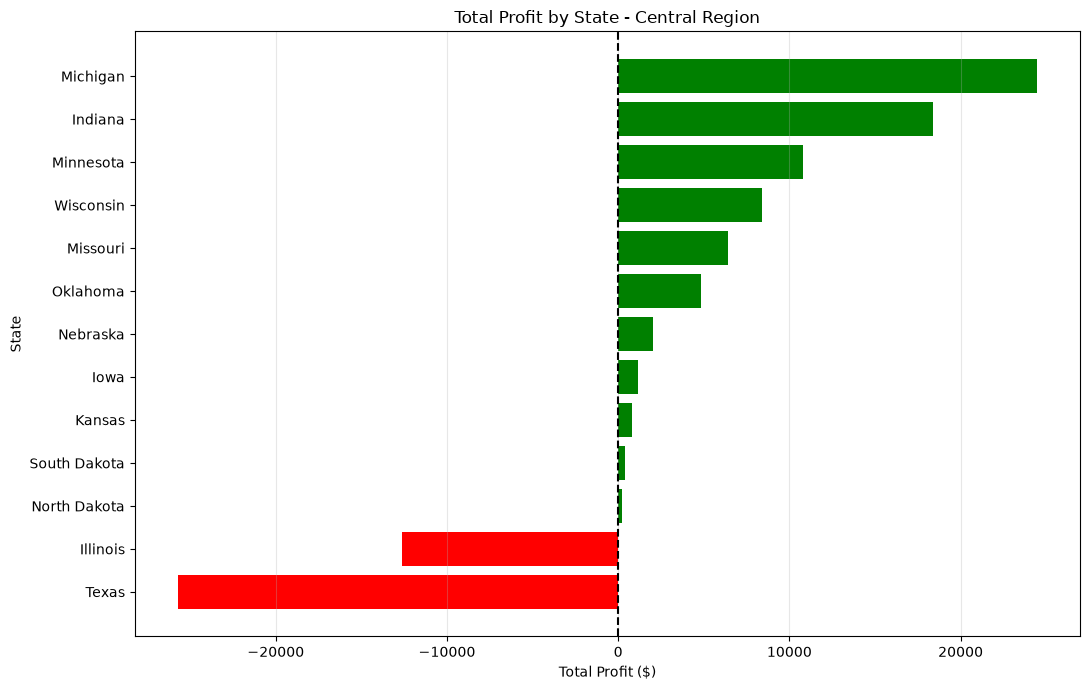

In [42]:
state_sorted = state_performance.sort_values(
    "Total_Profit",
    ascending=True
)
colors = [
    "red" if profit < 0 else "green"
    for profit in state_sorted["Total_Profit"]
]
plt.figure(figsize=(11, 7))
plt.barh(
    state_sorted["State/Province"],
    state_sorted["Total_Profit"],
    color=colors
)
plt.title("Total Profit by State - Central Region")
plt.xlabel("Total Profit ($)")
plt.ylabel("State")
plt.axvline(x=0, color="black", linestyle="--")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [43]:
# Filter Texas and Illinois

loss_states = df[
    df["State/Province"].isin(["Texas", "Illinois"])
].copy()
loss_states.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Order Year
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512,2023
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870,2023
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717,2023
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748,2023
14,15,US-2023-105417,2023-01-07,2023-01-12,Standard Class,VS-21820,Vivek Sundaresam,Consumer,United States,Huntsville,...,Central,FUR-FU-10004864,Furniture,Furnishings,"Howard Miller 14-1/2"" Diameter Chrome Round Wa...",76.728,3,0.6,-53.7096,2023


In [44]:
# Calculate category performance by state

state_category_performance = loss_states.groupby(
    ["State/Province", "Category"]
).agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Average_Discount=("Discount", "mean"),
    Total_Quantity=("Quantity", "sum")
).reset_index()
state_category_performance

,State/Province,Category,Total_Sales,Total_Profit,Average_Discount,Total_Quantity
0,Illinois,Furniture,28274.5220,-9076.2894,0.468293,448
1,Illinois,Office Supplies,19907.9060,-8354.1568,0.410526,1095
2,Illinois,Technology,31983.6730,4822.5592,0.205952,302
3,Texas,Furniture,60593.2918,-10436.1419,0.422970,766
4,Texas,Office Supplies,44490.5300,-18584.6434,0.398675,2299
5,Texas,Technology,65104.2240,3291.4290,0.214525,659


In [45]:
# Calculate profit margin

state_category_performance["Profit_Margin"] = (
    state_category_performance["Total_Profit"] / 
    state_category_performance["Total_Sales"]
) * 100

state_category_performance["Average_Discount"] *= 100

state_category_performance = state_category_performance.sort_values(
    "Total_Profit",
    ascending=True
)
state_category_performance.round(2)

,State/Province,Category,Total_Sales,Total_Profit,Average_Discount,Total_Quantity,Profit_Margin
4,Texas,Office Supplies,44490.53,-18584.64,39.87,2299,-41.77
3,Texas,Furniture,60593.29,-10436.14,42.30,766,-17.22
0,Illinois,Furniture,28274.52,-9076.29,46.83,448,-32.10
1,Illinois,Office Supplies,19907.91,-8354.16,41.05,1095,-41.96
5,Texas,Technology,65104.22,3291.43,21.45,659,5.06
2,Illinois,Technology,31983.67,4822.56,20.60,302,15.08


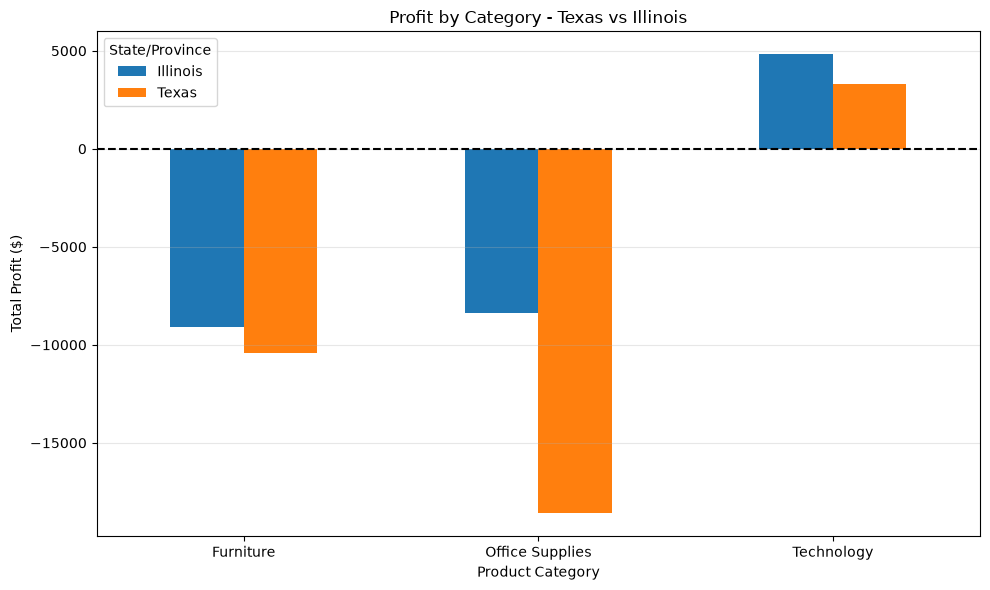

In [46]:
profit_comparison = state_category_performance.pivot(
    index="Category",
    columns="State/Province",
    values="Total_Profit"
)
ax = profit_comparison.plot(
    kind="bar",
    figsize=(10, 6)
)
plt.title("Profit by Category - Texas vs Illinois")
plt.xlabel("Product Category")
plt.ylabel("Total Profit ($)")
plt.axhline(y=0, color="black", linestyle="--")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

#### 4.4 Sub-Category Profitability — Texas & Illinois

**Objective:**

Identify the subcategories generating the largest financial losses within Furniture and Office Supplies in Texas and Illinois.

The analysis will help identify underperforming product groups that require further investigation.


In [47]:
selected_categories = loss_states[
    loss_states["Category"].isin(["Furniture", "Office Supplies"])
].copy()
selected_categories.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Order Year
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512,2023
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870,2023
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717,2023
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748,2023
14,15,US-2023-105417,2023-01-07,2023-01-12,Standard Class,VS-21820,Vivek Sundaresam,Consumer,United States,Huntsville,...,Central,FUR-FU-10004864,Furniture,Furnishings,"Howard Miller 14-1/2"" Diameter Chrome Round Wa...",76.728,3,0.6,-53.7096,2023


In [48]:
# Calculate performance by sub-category

subcategory_performance = selected_categories.groupby(
    ["State/Province", "Category", "Sub-Category"]
).agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Average_Discount=("Discount", "mean"),
    Total_Quantity=("Quantity", "sum")
).reset_index()

# Calculate profit margin
subcategory_performance["Profit_Margin"] = (
    subcategory_performance["Total_Profit"] /
    subcategory_performance["Total_Sales"]
) * 100
# Convert discount to percentage
subcategory_performance["Average_Discount"] *= 100

subcategory_performance = subcategory_performance.sort_values(
    "Total_Profit",
    ascending=True
)
subcategory_performance.head(10).round(2)

,State/Province,Category,Sub-Category,Total_Sales,Total_Profit,Average_Discount,Total_Quantity,Profit_Margin
19,Texas,Office Supplies,Binders,9042.68,-14705.07,80.0,626,-162.62
6,Illinois,Office Supplies,Binders,4538.55,-7204.32,80.0,327,-158.74
17,Texas,Office Supplies,Appliances,2407.81,-6147.22,80.0,159,-255.30
3,Illinois,Furniture,Tables,6550.67,-4309.74,50.0,65,-65.79
15,Texas,Furniture,Furnishings,3766.72,-3312.68,60.0,308,-87.95
2,Illinois,Furniture,Furnishings,2877.98,-2631.98,60.0,193,-91.45
14,Texas,Furniture,Chairs,26572.45,-2515.65,30.0,235,-9.47
4,Illinois,Office Supplies,Appliances,974.72,-2482.42,80.0,76,-254.68
13,Texas,Furniture,Bookcases,14493.46,-2391.14,32.0,105,-16.50
16,Texas,Furniture,Tables,15760.66,-2216.68,30.0,118,-14.06


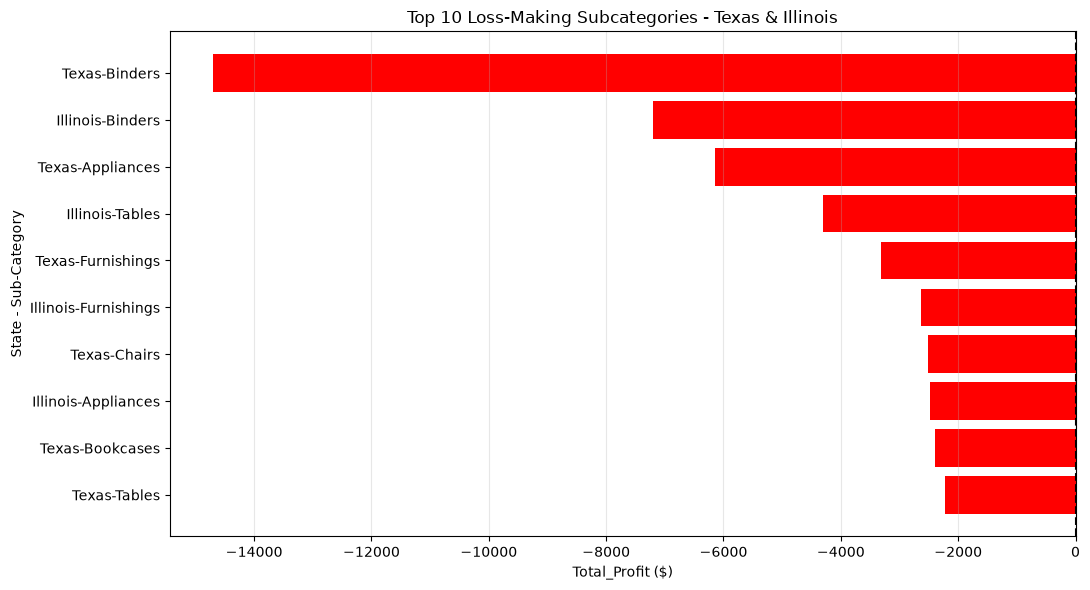

In [50]:
# Select the 10 worst-performing state-subcategory combinations

top_10_losses = subcategory_performance.nsmallest(
    10, "Total_Profit"
).copy()
# Create labels combining stste and sub-category
top_10_losses["Label"] = (
    top_10_losses["State/Province"] + "-" +
    top_10_losses["Sub-Category"]
)
# Sort for visualisation
top_10_losses = top_10_losses.sort_values(
    "Total_Profit",
    ascending=False
)
# Create horizontal bar chart
plt.figure(figsize=(11, 6))
plt.barh(
    top_10_losses["Label"],
    top_10_losses["Total_Profit"],
    color="red"
)
plt.title("Top 10 Loss-Making Subcategories - Texas & Illinois")
plt.xlabel("Total_Profit ($)")
plt.ylabel("State - Sub-Category")
plt.axvline(x=0, color="black", linestyle="--")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


## Key Findings

- Technology is the most profitable category, while Furniture has the lowest profit margin.
- Higher discounts are associated with lower profitability, particularly for Tables and Bookcases.
- The Central region has the lowest profit margin, with significant losses in Texas and Illinois.

These findings will be combined with the Returns Analysis to develop the final business recommendations.